In [1]:
from hana_ml import dataframe
from hana_ml.algorithms.pal.utility import DataSets
from generative_ai_toolkit_for_sap_hana_cloud.tools.toolkit import HANAMLToolkit
from generative_ai_toolkit_for_sap_hana_cloud.vectorstore.hana_vector_engine import HANAMLinVectorEngine


In [2]:
url, port, user, pwd = "<HANA_HOST>.hana.demo-hc-3-haas-hc-dev.dev-aws.hanacloud.ondemand.com", 443, "<HANA_USER>", "<HANA_PASSWORD>"
connection_context = dataframe.ConnectionContext(url, port, user, pwd)
hana_df, _, _, _ = DataSets.load_iris_data(connection_context)
hana_df = hana_df.to_head("ID")

Table IRIS_DATA_FULL_TBL exists.


In [3]:
#create vectordb with full knowledge of hana-ml

toolkit = HANAMLToolkit()
hana_vec = HANAMLinVectorEngine(connection_context, "hana_vec_hana_ml_knowledge")
hana_vec.create_knowledge()
toolkit.set_vectordb(hana_vec)


100%|██████████| 1/1 [00:21<00:00, 21.88s/it]


In [4]:
hana_vec.query("abc_analysis")

"\nHere is a Python code template based on the provided help doc:\n\n```python\n# Import necessary libraries\nfrom hana_ml.algorithms.pal import abc_analysis\n\n# Perform abc_analysis\nresult = abc_analysis(\n    data=data, \n    key='ITEM', \n    percent_A=0.7, \n    percent_B=0.2, \n    percent_C=0.1, \n    thread_ratio=0.3\n)\n\n# Print the result\nprint(result)\n```\n\nPlease replace the DataFrame `data` with your actual data. The `key` parameter should be the name of the ID column in your data. The `percent_A`, `percent_B`, and `percent_C` parameters should be the proportions allocated to A, B, and C classes respectively. The `thread_ratio` parameter specifies the ratio of total number of threads that can be used by this function."

In [6]:
hana_vec.get_knowledge().collect()

,id,description,example,embeddings
0,abc_analysis,The abc_analysis function in the hana_ml.algor...,\nHere is a Python code template based on the ...,"[-0.02208906039595604, 0.04436293989419937, -0..."
1,accuracy_measure,The accuracy_measure function in the hana_ml.a...,\nHere is the executable code template for the...,"[0.004033094272017479, 0.04234658554196358, -0..."
2,accuracy_score,The accuracy_score function in the hana_ml.alg...,\nHere is a Python code template based on the ...,"[0.008136419579386711, 0.029762445017695427, -..."
3,AdditiveModelForecastExplainer,The AdditiveModelForecastExplainer class in th...,\nHere is a Python code template for the `Addi...,"[-0.01599763333797455, -0.0254523828625679, 0...."
4,AffinityPropagation,The AffinityPropagation class in the hana_ml.a...,\nHere is a Python code template based on the ...,"[0.010633992031216621, -0.016167793422937393, ..."
...,...,...,...,...
261,wilcoxon,The wilcoxon function in the hana_ml.algorithm...,\nHere is the executable code template based o...,"[-0.024010619148612022, 0.0010517763439565897,..."
262,WordCloud,The WordCloud class in the hana_ml.visualizers...,\nHere is a Python code template for the `Word...,"[-0.006890767719596624, -0.008703256957232952,..."
263,wpdec,The wpdec function in the hana_ml.algorithms.p...,\nHere is the executable code template based o...,"[-0.03770582750439644, 0.015094058588147163, -..."
264,wprec,The wprec function in the hana_ml.algorithms.p...,\nHere is a Python code template based on the ...,"[-0.04031224921345711, -0.00893762893974781, -..."


In [4]:
from gen_ai_hub.proxy.langchain import init_llm
llm = init_llm('gpt-4', temperature=0.0, max_tokens=512)

In [5]:
from generative_ai_toolkit_for_sap_hana_cloud.smart_dataframe import SmartDataFrame

sdf = SmartDataFrame(hana_df)

In [6]:
sdf.configure(toolkit=toolkit, llm=llm)



> Entering new AgentExecutor chain...
Thought: To create a dataset report, I need to use the `create_report` function from the `Dataframe` class in the `hana_ml` library. This function generates a report about the dataset, including information about the columns, the number of missing values, the number of unique values, and basic statistics like mean, median, mode, min, max, etc.
Action: CodeTemplatesFromVectorDB
Action Input: create_report
Observation: 
>>> from hana_ml.visualizers.unified_report import UnifiedReport
>>> UnifiedReport(<data_frame>).build(key=None).display()
Thought:I now know how to create a dataset report using the `UnifiedReport` class from the `hana_ml.visualizers.unified_report` module. I need to create an instance of `UnifiedReport` with the dataframe as an argument, then call the `build` method on it, and finally call the `display` method to show the report.
Action: python_repl_ast
Action Input: 
from hana_ml.visualizers.unified_report import UnifiedReport
re


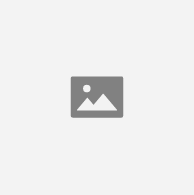


Observation: 
Thought:The report has been created and displayed successfully.
Final Answer: The dataset report has been created and displayed.

> Finished chain.


{'input': 'Create dataset report',
 'output': 'The dataset report has been created and displayed.'}

In [14]:
sdf.ask("Create dataset report", verbose=True)

In [66]:
connection_context.drop_table("my_model")

ERROR:hana_ml.dataframe:Fail to drop table. (259, 'invalid table name: my_model: line 1 col 23 (at pos 22)')


In [67]:
sdf.ask("Create Automatic Classification model on this dataframe with max_eval_time_mins=10. Provide key is ID, background_size is 100, label is SPECIES and model table is 'my_model' in the fit function and execute it. ", verbose=True)



> Entering new AgentExecutor chain...
Thought: To create an Automatic Classification model, I need to import the necessary module from hana_ml and instantiate the model. Then, I need to fit the model to the dataframe using the specified parameters.
Action: CodeTemplatesFromVectorDB
Action Input: Create Automatic Classification model
Observation: 
Strictly use the Examples to create AutoML instance.
Do fitting:
>>> from hana_ml.algorithms.pal.auto_ml import AutomaticClassification
>>> mymodel = AutomaticClassification(generations=2, population_size=5, offspring_size=5, max_eval_time_mins=10, successive_halving=True)
>>> mymodel.enable_workload_class(<WORKLOAD_CLASS>)
>>> mymodel.fit(data=<data_frame>, key=<ID>, model_table_name=<MODEL_TABLE>, background_size=<background_size>)
Thought:

ERROR:hana_ml.ml_exceptions:Please define the workload class and call the enable_workload_class() method first!
ERROR:hana_ml.ml_exceptions:Please define the workload class and call the enable_workload_class() method first!


I now know how to create an Automatic Classification model and fit it to the dataframe. I need to replace the placeholders in the code with the actual values.
Action: python_repl_ast
Action Input: 
from hana_ml.algorithms.pal.auto_ml import AutomaticClassification
mymodel = AutomaticClassification(generations=2, population_size=5, offspring_size=5, max_eval_time_mins=10, successive_halving=True)
mymodel.fit(data=df, key='ID', model_table_name='my_model', background_size=100, label='SPECIES')
Observation: FitIncompleteError: Please define the workload class and call the enable_workload_class() method first!
Thought:I forgot to enable the workload class before fitting the model. I need to enable it and then fit the model again.
Action: python_repl_ast
Action Input: 
mymodel.enable_workload_class('L')
mymodel.fit(data=df, key='ID', model_table_name='my_model', background_size=100, label='SPECIES')


Observation: <hana_ml.algorithms.pal.auto_ml.AutomaticClassification object at 0x000001DA31056A50>
Thought:The model has been successfully created and fitted to the dataframe.
Final Answer: The Automatic Classification model has been created and fitted to the dataframe with the specified parameters.

> Finished chain.


{'input': "Create Automatic Classification model on this dataframe with max_eval_time_mins=10. Provide key is ID, background_size is 100, label is SPECIES and model table is 'my_model' in the fit function and execute it. ",
 'output': 'The Automatic Classification model has been created and fitted to the dataframe with the specified parameters.'}

In [68]:
connection_context.table("my_model").collect()

,ROW_INDEX,MODEL_CONTENT
0,0,"{""pipeline"":{""DT_Classifier"":{""args"":{""ALGORIT..."


In [69]:
sdf.ask("Show the samples of the dataset", verbose=True)



> Entering new AgentExecutor chain...
Thought: To show the samples of the dataset, I need to use the `head()` function on the dataframe `df`.
Action: python_repl_ast
Action Input: df.head().collect()
Observation:    ID  SEPALLENGTHCM  SEPALWIDTHCM  PETALLENGTHCM  PETALWIDTHCM      SPECIES
0   0            5.1           3.5            1.4           0.2  Iris-setosa
Thought:I now know the final answer
Final Answer: The samples of the dataset are as follows:
   ID  SEPALLENGTHCM  SEPALWIDTHCM  PETALLENGTHCM  PETALWIDTHCM      SPECIES
0   0            5.1           3.5            1.4           0.2  Iris-setosa

> Finished chain.


{'input': 'Show the samples of the dataset',
 'output': 'The samples of the dataset are as follows:\n   ID  SEPALLENGTHCM  SEPALWIDTHCM  PETALLENGTHCM  PETALWIDTHCM      SPECIES\n0   0            5.1           3.5            1.4           0.2  Iris-setosa'}

In [70]:
new_df = sdf.transform("Get first two rows", verbose=True)



> Entering new AgentExecutor chain...
Thought: To get the first two rows, I need to use the head() function with parameter 2. Then, I need to save the result to trans_df and return the SQL string from calling trans_df.select_statement.

Action: python_repl_ast
Action Input: 
```python
trans_df = df.head(2)
sql_string = trans_df.select_statement
sql_string
```
Observation: SELECT TOP 2 * FROM (SELECT "ID", "SEPALLENGTHCM", "SEPALWIDTHCM", "PETALLENGTHCM", "PETALWIDTHCM", "SPECIES" FROM (SELECT * FROM "PAL_TEST"."IRIS_DATA_FULL_TBL") AS "DT_585") dt
Thought:Final Answer: SELECT TOP 2 * FROM (SELECT "ID", "SEPALLENGTHCM", "SEPALWIDTHCM", "PETALLENGTHCM", "PETALWIDTHCM", "SPECIES" FROM (SELECT * FROM "PAL_TEST"."IRIS_DATA_FULL_TBL") AS "DT_585") dt

> Finished chain.
